In [33]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, VotingRegressor, StackingRegressor)
from sklearn.model_selection import GridSearchCV, KFold

In [12]:
df = pd.read_csv('Medical_Insurance_cost_prediction.csv')

In [13]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [15]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


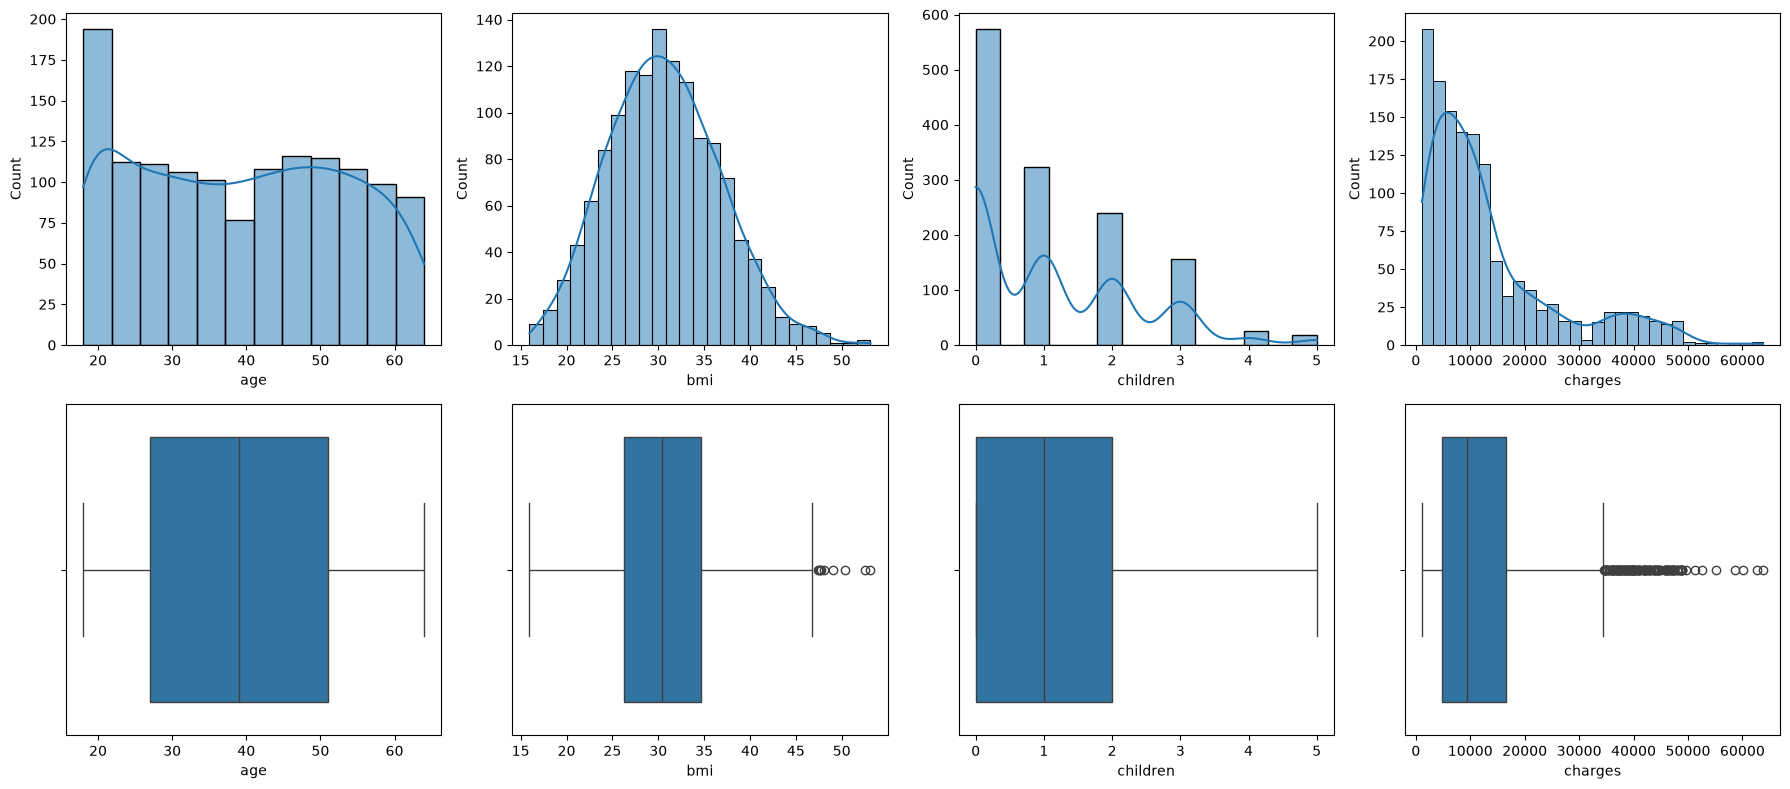

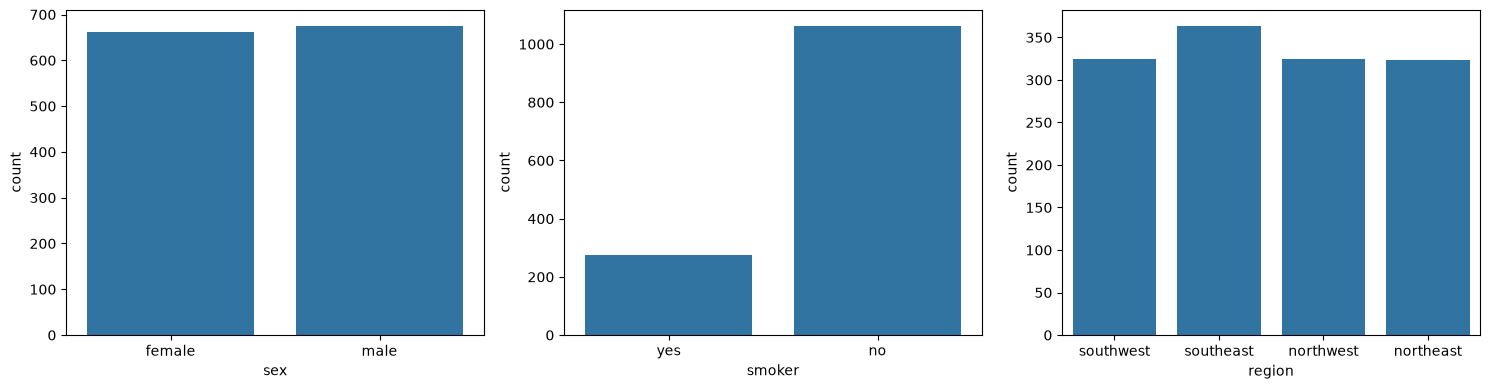

In [16]:
numeric = ["age", "bmi", "children", "charges"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(numeric):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(["sex", "smoker", "region"]):
    sns.countplot(x=df[col], ax=axes[i])
plt.tight_layout(); plt.show()

charges     1.000000
smoker      0.787251
age         0.299008
bmi         0.198341
children    0.067998
sex         0.057292
region     -0.006208
Name: charges, dtype: float64


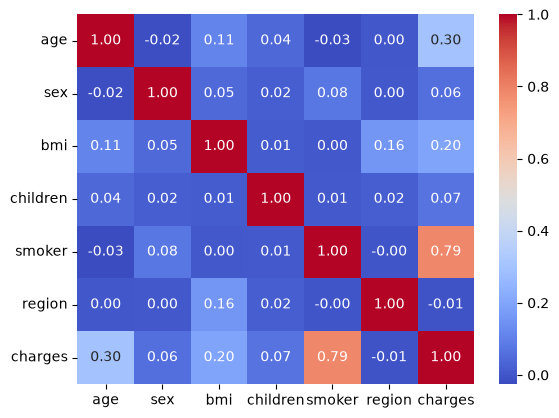

In [17]:
d = df.copy()
d["sex"] = d["sex"].map({"male": 1, "female": 0})
d["smoker"] = d["smoker"].map({"yes": 1, "no": 0})
d["region"] = d["region"].map({"northeast": 0, "northwest": 1, "southeast": 2, "southwest": 3})

print(d.corr()["charges"].sort_values(ascending=False))
sns.heatmap(d.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

Skewness:
 age         0.06
bmi         0.28
children    0.94
charges     1.52
dtype: float64


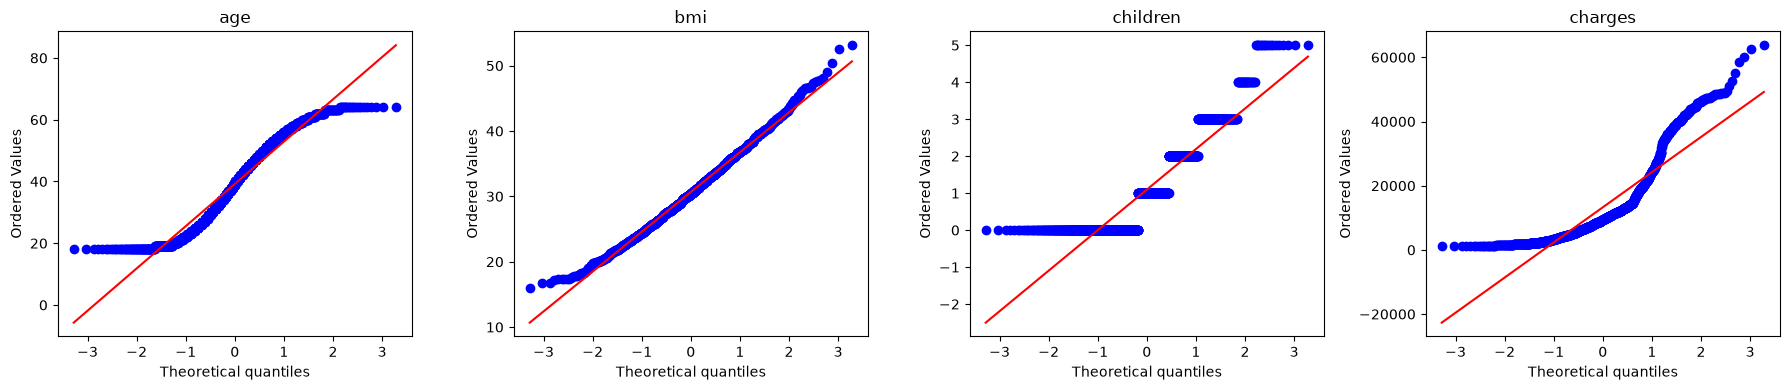

In [20]:
print("Skewness:\n", df[numeric].skew().round(2))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, numeric):
    stats.probplot(df[col], plot=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

In [21]:
##smoker is the strongest driver of charges (r = 0.79). Smokers pay about 3.8 times more on average.
##age (r = 0.30) and bmi (r = 0.20) have moderate effects. BMI matters mainly for smokers.
##sex, region and children are weak.
##charges is strongly right-skewed (1.52), so it gets a log transform. age and bmi are roughly symmetric.
##The features are barely correlated with each other, so multicollinearity isn’t a concern.


In [22]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1
(1337, 7)


In [23]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["age", "bmi", "children", "charges"]:
    lo, hi = iqr_bounds(df[col])
    print(col, "outliers:", ((df[col] < lo) | (df[col] > hi)).sum())

age outliers: 0
bmi outliers: 9
children outliers: 0
charges outliers: 139


In [24]:
df["sex"] = df["sex"].map({"male": 1, "female": 0})
df["smoker"] = df["smoker"].map({"yes": 1, "no": 0})
df["region"] = df["region"].map({"northeast": 0, "northwest": 1, "southeast": 2, "southwest": 3})

In [27]:
scale_cols = ["age", "bmi", "children"]
df[scale_cols] = StandardScaler().fit_transform(df[scale_cols])
df.describe().round(2)

,age,sex,bmi,children,smoker,region,charges
count,1337.00,1337.0,1337.00,1337.00,1337.0,1337.00,1337.00
mean,-0.00,0.5,-0.00,0.00,0.2,1.52,13279.12
std,1.00,0.5,1.00,1.00,0.4,1.11,12110.36
min,-1.51,0.0,-2.41,-0.91,0.0,0.00,1121.87
25%,-0.87,0.0,-0.72,-0.91,0.0,1.00,4746.34
50%,-0.02,1.0,-0.04,-0.08,0.0,2.00,9386.16
75%,0.84,1.0,0.66,0.75,0.0,2.00,16657.72
max,1.76,1.0,3.68,3.24,1.0,3.00,63770.43


In [29]:
X = df.drop(columns="charges")
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=df["smoker"])

In [30]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVR": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    # ---- ensemble methods ----
    "Bagging": BaggingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
models["Voting (RF+GB+LR)"] = VotingRegressor([
    ("rf", models["Random Forest"]), ("gb", models["Gradient Boosting"]), ("lr", models["Linear Regression"])])
models["Stacking"] = StackingRegressor(
    estimators=[("rf", RandomForestRegressor(random_state=42)),
                ("gb", GradientBoostingRegressor(random_state=42)),
                ("knn", make_pipeline(StandardScaler(), KNeighborsRegressor()))],
    final_estimator=LinearRegression())

In [31]:
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"Model": name,
                 "Train R2": r2_score(y_train, m.predict(X_train)),
                 "Test R2": r2_score(y_test, p),
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p))})
results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).round(3)
results

,Model,Train R2,Test R2,MAE,RMSE
9,Stacking,0.921,0.869,2364.676,4310.968
7,Gradient Boosting,0.903,0.869,2403.744,4316.857
8,Voting (RF+GB+LR),0.912,0.860,2674.745,4464.051
2,Random Forest,0.975,0.843,2641.050,4722.125
3,SVR,0.844,0.838,1907.599,4792.022
5,Bagging,0.967,0.823,2850.986,5013.663
4,KNN,0.867,0.821,3050.072,5039.491
6,AdaBoost,0.842,0.815,3906.277,5128.634
0,Linear Regression,0.744,0.765,3954.150,5778.751
1,Decision Tree,0.998,0.649,3413.824,7061.624


In [32]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate(y_true, y_pred, n_features):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2,
            "Adj R2": adjusted_r2(r2, len(y_true), n_features)}

rows = []
p = X_train.shape[1]                      # number of features
for name, m in models.items():
    m.fit(X_train, y_train)
    tr = evaluate(y_train, m.predict(X_train), p)
    te = evaluate(y_test,  m.predict(X_test),  p)
    row = {"Model": name}
    for k in tr:
        row[f"Train {k}"] = tr[k]
        row[f"Test {k}"] = te[k]
    row["R2 gap"] = tr["R2"] - te["R2"]            # train R2 minus test R2
    row["Fit"] = ("Overfit" if row["R2 gap"] > 0.05
                  else "Underfit" if te["R2"] < 0.75
                  else "Good fit")
    rows.append(row)

results = pd.DataFrame(rows).set_index("Model").sort_values("Test R2", ascending=False).round(3)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
results

,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2,Train Adj R2,Test Adj R2,R2 gap,Fit
Model,,,,,,,,,,,,
Stacking,1848.172,2364.676,1.176433e+07,1.858445e+07,3429.917,4310.968,0.921,0.869,0.920,0.867,0.052,Overfit
Gradient Boosting,2072.276,2403.744,1.445813e+07,1.863525e+07,3802.385,4316.857,0.903,0.869,0.902,0.867,0.034,Good fit
Voting (RF+GB+LR),2248.449,2674.745,1.303065e+07,1.992775e+07,3609.799,4464.051,0.912,0.860,0.912,0.858,0.052,Overfit
Random Forest,1044.673,2641.050,3.722744e+06,2.229847e+07,1929.441,4722.125,0.975,0.843,0.975,0.841,0.132,Overfit
SVR,1734.276,1907.599,2.310001e+07,2.296348e+07,4806.247,4792.022,0.844,0.838,0.843,0.836,0.006,Good fit
Bagging,1146.601,2850.986,4.852129e+06,2.513682e+07,2202.755,5013.663,0.967,0.823,0.967,0.820,0.144,Overfit
KNN,2667.633,3050.072,1.971926e+07,2.539647e+07,4440.637,5039.491,0.867,0.821,0.866,0.819,0.046,Good fit
AdaBoost,3697.775,3906.277,2.339787e+07,2.630289e+07,4837.135,5128.634,0.842,0.815,0.841,0.812,0.027,Good fit
Linear Regression,4199.564,3954.150,3.795666e+07,3.339396e+07,6160.897,5778.751,0.744,0.765,0.743,0.761,-0.021,Good fit


In [34]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# model + search space (inside a pipeline, parameters need the step name + "__")
searches = {
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42), {
        "n_estimators": [100, 200, 300],
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0]}),
    "Random Forest": (RandomForestRegressor(random_state=42), {
        "n_estimators": [200, 400],
        "max_depth": [4, 6, 8, None],
        "min_samples_leaf": [1, 3, 5, 10],
        "max_features": [0.5, 1.0]}),
    "SVR": (make_pipeline(StandardScaler(), SVR()), {
        "svr__C": [1000, 5000, 10000, 20000],
        "svr__gamma": ["scale", 0.01, 0.1],
        "svr__epsilon": [0.1, 10, 100]}),
    "KNN": (make_pipeline(StandardScaler(), KNeighborsRegressor()), {
        "kneighborsregressor__n_neighbors": [3, 5, 7, 9, 12, 15],
        "kneighborsregressor__weights": ["uniform", "distance"],
        "kneighborsregressor__p": [1, 2]}),
}

def scores(m):
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    return {"Train R2": r2_score(y_train, p_tr), "Test R2": r2_score(y_test, p_te),
            "Test MAE": mean_absolute_error(y_test, p_te),
            "Test RMSE": np.sqrt(mean_squared_error(y_test, p_te))}

rows, best_params, tuned = [], {}, {}
for name, (est, grid) in searches.items():
    est.fit(X_train, y_train)                      # before tuning (default settings)
    before = scores(est)

    gs = GridSearchCV(est, grid, cv=kf, scoring="r2", n_jobs=-1)   # tuning, training data only
    gs.fit(X_train, y_train)
    after = scores(gs.best_estimator_)

    best_params[name] = gs.best_params_
    tuned[name] = gs.best_estimator_
    rows.append({"Model": name,
                 "Before Test R2": before["Test R2"], "After Test R2": after["Test R2"],
                 "R2 gain": after["Test R2"] - before["Test R2"],
                 "Before Test MAE": before["Test MAE"], "After Test MAE": after["Test MAE"],
                 "Before Test RMSE": before["Test RMSE"], "After Test RMSE": after["Test RMSE"],
                 "After Train R2": after["Train R2"], "CV R2": gs.best_score_})

tuning = pd.DataFrame(rows).set_index("Model").sort_values("After Test R2", ascending=False).round(3)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print(tuning)
for name, bp in best_params.items():
    print(name, "->", bp)

                   Before Test R2  After Test R2  R2 gain  Before Test MAE  After Test MAE  Before Test RMSE  After Test RMSE  After Train R2  CV R2
Model                                                                                                                                               
Random Forest               0.843          0.867    0.024         2641.050        2450.174          4722.125         4345.102           0.875  0.847
Gradient Boosting           0.869          0.865   -0.003         2403.744        2486.497          4316.857         4372.762           0.872  0.848
SVR                        -0.103          0.842    0.945         8213.662        1945.416         12520.260         4739.586           0.844  0.827
KNN                         0.821          0.831    0.009         3050.072        2919.078          5039.491         4904.446           0.998  0.793
Gradient Boosting -> {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
Random

In [35]:
table_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": tuned["Random Forest"],
    "Gradient Boosting": tuned["Gradient Boosting"],
}

def row_for(name, m):
    m.fit(X_train, y_train)
    tr, te = m.predict(X_train), m.predict(X_test)
    gap = r2_score(y_train, tr) - r2_score(y_test, te)
    return {"Model": name,
            "Train RMSE": np.sqrt(mean_squared_error(y_train, tr)),
            "Test RMSE": np.sqrt(mean_squared_error(y_test, te)),
            "Train R²": r2_score(y_train, tr),
            "Test R²": r2_score(y_test, te),
            "Overfitting (Y/N)": "Y" if gap > 0.05 else "N"}

rows = [row_for(n, m) for n, m in table_models.items()]

# last row: the best model by test R² among the four
best = max(rows, key=lambda r: r["Test R²"])
rows.append({**best, "Model": f"Best Model ({best['Model']})"})

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Train RMSE,Test RMSE,Train R²,Test R²,Overfitting (Y/N)
Model,,,,,
Linear Regression,6160.897,5778.751,0.744,0.765,N
Decision Tree,528.681,7061.624,0.998,0.649,Y
Random Forest,4302.252,4345.102,0.875,0.867,N
Gradient Boosting,4361.855,4372.762,0.872,0.865,N
Best Model (Random Forest),4302.252,4345.102,0.875,0.867,N
